# Лабораторная работа 5. Позиционное кодирование и RoPE (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 2:** attention и архитектура трансформера

**Цель.** Понять, как трансформер получает информацию о порядке токенов и почему модели плохо работают на длинах контекста, которых не видели при обучении.

**Что нужно сдать:**
1. Единый интерфейс для пяти вариантов: NoPE, синусоидального, обучаемого, ALiBi и RoPE.
2. Численную проверку относительности RoPE и график затухания верхней границы.
3. Таблицу «кодирование × длина контекста» для символьной LM (экстраполяция длины).
4. Position interpolation и NTK-aware scaling для RoPE без дообучения и после короткого дообучения.
5. Тест «иголка в стоге сена» на синтетической задаче поиска.

**Теория.** RoPE поворачивает пары координат $(x_{2i}, x_{2i+1})$ на угол $m\theta_i$, где $\theta_i = b^{-2i/d}$, а $m$ — позиция. В комплексной записи $\tilde q_m = q\,e^{im\theta}$, $\tilde k_n = k\,e^{in\theta}$, поэтому
$$
\mathrm{Re}\langle \tilde q_m, \tilde k_n\rangle = \mathrm{Re}\sum_i q_i \bar k_i\, e^{i(m-n)\theta_i},
$$
то есть скалярное произведение зависит только от разности позиций $m - n$.

**Расширение контекста в $s$ раз:**
- position interpolation: $m \mapsto m/s$;
- NTK-aware scaling: $b \mapsto b\, s^{d/(d-2)}$ — высокие частоты почти не меняются, низкие интерполируются.


In [2]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.15.0+cpu, device=cpu, FAST_DEV_RUN=True


## 1. Позиционные кодирования

In [ ]:
def sinusoidal_pe(T, d):
    m = torch.arange(T, dtype=torch.float32)[:, None]          # (T, 1)
    i = torch.arange(d // 2, dtype=torch.float32)[None, :]    # (1, d/2)
    theta = 10000.0 ** (-2 * i / d)                            # (1, d/2)
    ang = m * theta                                            # (T, d/2)
    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(ang)
    pe[:, 1::2] = torch.cos(ang)
    return pe

def rope_angles(T, d, base=10000.0, scale=1.0):
    """Углы m*theta_i, форма (T, d/2). scale > 1 — position interpolation."""
    m = torch.arange(T, dtype=torch.float32)[:, None] / scale
    i = torch.arange(d // 2, dtype=torch.float32)[None, :]
    theta = base ** (-2 * i / d)
    return m * theta

def apply_rope(x, ang):
    """x: (..., T, d), ang: (T, d/2). Поворачивает пары (x[2i], x[2i+1])."""
    x1, x2 = x[..., 0::2], x[..., 1::2]                        # (..., T, d/2)
    cos, sin = ang.cos(), ang.sin()                            # (T, d/2)

    y1 = x1 * cos - x2 * sin
    y2 = x1 * sin + x2 * cos
    y = torch.empty_like(x)
    y[..., 0::2] = y1
    y[..., 1::2] = y2
    return y

def alibi_bias(T, n_head):
    """Смещение -m_h * (i - j) для j <= i; m_h = 2^{-8h/H}, h = 1..H. Форма (H, T, T)."""
    slopes = torch.tensor([2.0 ** (-8 * (h + 1) / n_head) for h in range(n_head)])  # (H,)
    pos = torch.arange(T, dtype=torch.float32)
    dist = (pos[:, None] - pos[None, :]).clamp(min=0)          # (T, T), j<=i
    bias = -slopes[:, None, None] * dist[None]                 # (H, T, T)

    causal = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
    bias = bias.masked_fill(causal[None], float("-inf"))
    return bias

### Проверка относительности RoPE

Для случайных $q, k$ проверьте, что $\langle R_m q, R_n k\rangle$ зависит только от $m - n$, и постройте $\frac{1}{d/2}\big|\sum_i e^{i r \theta_i}\big|$ в зависимости от расстояния $r$ — величину, определяющую затухание верхней границы скалярного произведения при одинаковых $q, k$.


m=   5, n=   2: <R_m q, R_n k> = -8.281103
m= 105, n= 102: <R_m q, R_n k> = -8.281105
m=1005, n=1002: <R_m q, R_n k> = -8.281061


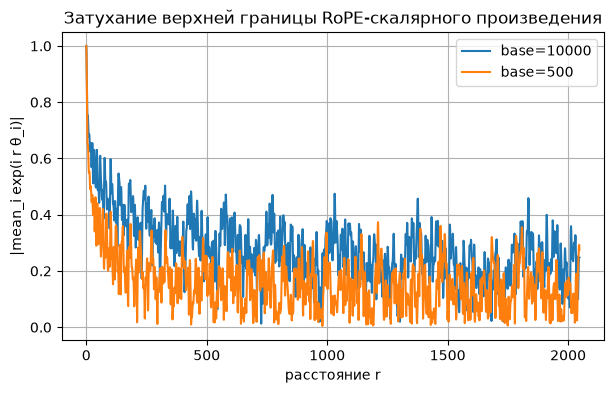

In [ ]:
d = 64; torch.manual_seed(0); 
q, k = torch.randn(d), torch.randn(d)
ang = rope_angles(2048, d)

def rot_dot(m, n): 
    return (apply_rope(q[None], ang[m:m + 1])[0] @ apply_rope(k[None], ang[n:n + 1])[0]).item()

for (m, n) in [(5, 2), (105, 102), (1005, 1002)]:
    print(f"m={m:4d}, n={n:4d}: <R_m q, R_n k> = {rot_dot(m, n):.6f}")
assert abs(rot_dot(5, 2) - rot_dot(1005, 1002)) < 1e-3

# (постройте |mean_i exp(i r theta_i)| для r = 0..2048 при base=10000 и base=500)
rs = torch.arange(0, 2048)

def decay_curve(base):
    th = base ** (-2 * torch.arange(d // 2, dtype=torch.float32) / d)
    re = torch.cos(rs[:, None] * th[None, :]).mean(-1)
    im = torch.sin(rs[:, None] * th[None, :]).mean(-1)
    return torch.sqrt(re**2 + im**2)

plt.figure(figsize=(7, 4))
for base in (10000.0, 500.0):
    plt.plot(rs.numpy(), decay_curve(base).numpy(), label=f"base={base:g}")
plt.xlabel("расстояние r"); plt.ylabel("|mean_i exp(i r θ_i)|")
plt.legend(); plt.title("Затухание верхней границы RoPE-скалярного произведения")
plt.grid(True); plt.show()

## 2. Трансформер с переключаемым позиционным кодированием

In [ ]:
class PEAttention(nn.Module):
    def __init__(self, d_model, n_head, pe):
        super().__init__()
        self.h, self.dh, self.pe = n_head, d_model // n_head, pe
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False); self.o = nn.Linear(d_model, d_model, bias=False)
        self.rope_base, self.rope_scale = 10000.0, 1.0
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = (t.view(B, T, self.h, self.dh).transpose(1, 2)
                   for t in self.qkv(x).split(C, 2))
        attn_mask = None
        if self.pe == "rope":
            ang = rope_angles(T, self.dh, base=self.rope_base, scale=self.rope_scale).to(x.device)
            q = apply_rope(q, ang) 
            k = apply_rope(k, ang)
        elif self.pe == "alibi":
            attn_mask = alibi_bias(T, self.h).to(x.device)
            attn_mask = attn_mask.unsqueeze(0).expand(B, -1, -1, -1)
        if attn_mask is None:
            causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1)
            attn_mask = torch.zeros(B, self.h, T, T, device=x.device)
            attn_mask = attn_mask.masked_fill(causal, float("-inf"))
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask)
        y = y.transpose(1, 2).reshape(B, T, C)
        return self.o(y)

class PETransformer(nn.Module):
    def __init__(self, vocab, pe, d_model=128, n_head=4, n_layer=2, max_T=64, mlp=True):
        super().__init__()
        self.pe, self.max_T = pe, max_T
        self.emb = nn.Embedding(vocab, d_model)
        if pe == "learned": self.pos = nn.Parameter(torch.randn(max_T, d_model) * 0.02)
        self.attn = nn.ModuleList([PEAttention(d_model, n_head, pe) for _ in range(n_layer)])
        self.ln1 = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layer)])
        self.ln2 = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layer)])
        self.mlp = nn.ModuleList([nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))
                                  if mlp else nn.Identity() for _ in range(n_layer)])
        self.use_mlp = mlp
        self.lnf, self.head = nn.LayerNorm(d_model), nn.Linear(d_model, vocab)
    def forward(self, x):
        T = x.size(1); h = self.emb(x)
        if self.pe == "sinusoidal": h = h + sinusoidal_pe(T, h.size(-1)).to(x.device)
        if self.pe == "learned":
            if T > self.max_T: raise ValueError("обучаемые позиции не определены за пределами обучающей длины")
            h = h + self.pos[:T]
        for a, l1, l2, m in zip(self.attn, self.ln1, self.ln2, self.mlp):
            h = h + a(l1(h))
            if self.use_mlp: h = h + m(l2(h))
        return self.head(self.lnf(h))
    def set_rope(self, base=10000.0, scale=1.0):
        for a in self.attn: a.rope_base, a.rope_scale = base, scale

PES = ["nope", "sinusoidal", "learned", "alibi", "rope"]

## 3. Экстраполяция длины на символьной LM

Обучите модели на окнах длины `T_TRAIN` и измерьте среднюю кросс-энтропию на окнах длины \(T_{train}\), \(2T_{train}\), \(4T_{train}\), \(8T_{train}\). Отдельно посчитайте loss только на позициях \(\ge T_{train}\) — это и есть качество экстраполяции.

In [ ]:
text = load_shakespeare(); chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text]); ntr = int(0.9 * len(data)); train_d, val_d = data[:ntr], data[ntr:]
T_TRAIN = 64 if FAST_DEV_RUN else 128
STEPS = 400 if FAST_DEV_RUN else 4000

def lm_batch(d, T, B=32):
    ix = torch.randint(len(d) - T - 1, (B,))
    return torch.stack([d[i:i + T] for i in ix]).to(DEVICE), torch.stack([d[i + 1:i + T + 1] for i in ix]).to(DEVICE)

def train_lm(model, steps, T, lr=2e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    for s in range(steps):
        x, y = lm_batch(train_d, T); loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten())
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    return model

@torch.no_grad()
def eval_lengths(model, lengths, n_windows=16):
    # (для каждой длины L — средний loss по всем позициям и по позициям >= T_TRAIN)
    model.eval()
    results = {}
    
    for L in lengths:
        try:
            x, y = lm_batch(val_d, L, B=n_windows)
            
            logits = model(x)
            
            loss_matrix = F.cross_entropy(
                logits.flatten(0, 1), 
                y.flatten(), 
                reduction='none'
            ).view(n_windows, L)
            
            mean_all = loss_matrix.mean().item()
            
            if L > T_TRAIN:
                mean_tail = loss_matrix[:, T_TRAIN:].mean().item()
            else:
                mean_tail = 0.0
                
            results[L] = (mean_all, mean_tail)
            
        except (ValueError, RuntimeError):
            results[L] = (float('nan'), float('nan') if L > T_TRAIN else 0.0)
        
    model.train() 
    return results

lengths = [T_TRAIN * m for m in (1, 2, 4, 8)]
lm_models, rows = {}, []
for pe in PES:
    set_seed(); t0 = time.time()
    lm_models[pe] = train_lm(PETransformer(len(chars), pe, max_T=T_TRAIN).to(DEVICE), STEPS, T_TRAIN)
    res = eval_lengths(lm_models[pe], lengths)
    rows.append({"PE": pe, **{f"L={L}": round(v[0], 3) for L, v in res.items()}, **{f"хвост L={L}": round(v[1], 3) for L, v in res.items() if L > T_TRAIN}})
    print(pe, f"{time.time() - t0:.0f} c")
import pandas as pd
pd.DataFrame(rows).set_index("PE")

nope 5 c
sinusoidal 5 c
learned 6 c
alibi 6 c
rope 7 c


,L=64,L=128,L=256,L=512,хвост L=128,хвост L=256,хвост L=512
PE,,,,,,,
nope,2.390,2.504,2.479,2.552,2.510,2.514,2.586
sinusoidal,2.044,2.653,2.990,3.144,3.222,3.314,3.311
learned,2.179,NaN,NaN,NaN,NaN,NaN,NaN
alibi,2.077,2.090,2.027,2.011,2.042,2.017,2.013
rope,1.934,2.128,2.392,2.811,2.226,2.524,2.944


## 4. Расширение контекста RoPE: position interpolation и NTK-aware scaling

Для RoPE-модели при длине \(L = s\,T_{train}\) сравните:
1. исходную модель;
2. position interpolation (`scale = s`);
3. NTK-aware scaling (`base = 10000 · s^{d/(d-2)}`).

Затем дообучите копии модели на длине \(L\) в течение короткого числа шагов (около 5% исходного обучения) с каждым вариантом и сравните снова.

In [ ]:
import copy
s_ext = 4; L_ext = s_ext * T_TRAIN; d_head = 128 // 4
variants = {
    "исходная": dict(base=10000.0, scale=1.0),
    "PI":       dict(base=10000.0, scale=float(s_ext)),
    "NTK":      dict(base=10000.0 * s_ext ** (d_head / (d_head - 2)), scale=1.0),
}

# (оцените варианты без дообучения и после короткого дообучения на длине L_ext)
def eval_rope_variant(base_model, L, base, scale, n_windows=16):
    m = copy.deepcopy(base_model); m.set_rope(base=base, scale=scale); m.eval()
    return eval_lengths(m, [L], n_windows=n_windows)

base_rope = lm_models["rope"]
rows = []
for name, cfg in variants.items():
    (tot, tail), = eval_rope_variant(base_rope, L_ext, **cfg).values()
    rows.append({"вариант": name, "режим": "без дообучения", "loss": tot, "tail": tail})


ft_steps = max(1, STEPS // 20)
for name, cfg in variants.items():
    m = copy.deepcopy(base_rope).to(DEVICE)
    m.set_rope(**cfg)
    opt = torch.optim.AdamW(m.parameters(), lr=5e-4, weight_decay=0.01)
    
    for _ in range(ft_steps):
        x, y = lm_batch(train_d, L_ext)
        loss = F.cross_entropy(m(x).flatten(0, 1), y.flatten())
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
    m.eval()
    (tot, tail), = eval_lengths(m, [L_ext]).values()
    rows.append({"вариант": name, "режим": "после дообучения", "loss": tot, "tail": tail})

pd.DataFrame(rows).set_index(["вариант", "режим"]).round(3)

,,loss,tail
вариант,режим,,
исходная,без дообучения,2.384,2.547
PI,без дообучения,3.006,3.055
NTK,без дообучения,2.131,2.203
исходная,после дообучения,1.877,1.895
PI,после дообучения,2.131,2.123
NTK,после дообучения,1.893,1.916


## 5. «Иголка в стоге сена»

Задача: последовательность пар `ключ значение` и в конце запрос-ключ; нужно вернуть значение (как в ЛР 4). Обучите attention-only модели (2 слоя, без MLP) на длине 32 и проверьте точность на длинах 32, 64, 128 (в полном режиме и 256). Запрос может относиться к паре в любом месте контекста.

In [ ]:
VOCAB_KV = 64

def needle_batch(T, B=128):
    # (n=(T-1)//2 пар; ключи различны в примере; цель — значение пары с ключом-запросом)
    n = (T - 1) // 2
    if n < 1:
        raise ValueError("T слишком мало")

    keys = torch.stack([torch.randperm(VOCAB_KV)[:n] for _ in range(B)])
    vals = torch.randint(0, VOCAB_KV, (B, n))

    j = torch.randint(0, n, (B, 1))
    q = keys.gather(1, j)
    target = vals.gather(1, j).squeeze(1)

    seq = torch.empty(B, 2 * n + 1, dtype=torch.long)
    seq[:, 0:2*n:2] = keys
    seq[:, 1:2*n:2] = vals
    seq[:, -1] = q.squeeze(1)

    return seq.to(DEVICE), target.to(DEVICE)

T_NEEDLE = 33
test_T = [33, 65, 129] if FAST_DEV_RUN else [33, 65, 129, 257]
rows = []
for pe in PES:
    set_seed(); m = PETransformer(VOCAB_KV, pe, n_layer=2, max_T=T_NEEDLE, mlp=False).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for s in range(800 if FAST_DEV_RUN else 4000):
        x, y = needle_batch(T_NEEDLE); loss = F.cross_entropy(m(x)[:, -1], y)
        opt.zero_grad(); loss.backward(); opt.step()
    r = {"PE": pe}
    with torch.no_grad():
        for T in test_T:
            try:
                x, y = needle_batch(T, B=512); r[f"T={T}"] = (m(x)[:, -1].argmax(-1) == y).float().mean().item()
            except ValueError:
                r[f"T={T}"] = float("nan")
    rows.append(r); print(r)
pd.DataFrame(rows).set_index("PE").round(3)

{'PE': 'nope', 'T=33': 0.201171875, 'T=65': 0.130859375, 'T=129': 0.083984375}
{'PE': 'sinusoidal', 'T=33': 0.078125, 'T=65': 0.037109375, 'T=129': 0.013671875}
{'PE': 'learned', 'T=33': 0.99609375, 'T=65': nan, 'T=129': nan}
{'PE': 'alibi', 'T=33': 0.6328125, 'T=65': 0.529296875, 'T=129': 0.42578125}
{'PE': 'rope', 'T=33': 0.896484375, 'T=65': 0.67578125, 'T=129': 0.26953125}


,T=33,T=65,T=129
PE,,,
nope,0.201,0.131,0.084
sinusoidal,0.078,0.037,0.014
learned,0.996,NaN,NaN
alibi,0.633,0.529,0.426
rope,0.896,0.676,0.270


## Вопросы

1. Докажите свойство относительности RoPE. Почему RoPE применяется к \(q\) и \(k\), но не к \(v\)?
2. Почему обучаемые позиционные эмбеддинги в принципе не экстраполируют, а синусоидальные формально определены, но на практике тоже плохо экстраполируют?
3. Как NoPE получает позиционную информацию в каузальной модели?
4. Объясните разницу между PI и NTK-aware scaling в терминах частот \(\theta_i\). Какие частоты «ломаются» при экстраполяции?
5. Как ALiBi реализует индуктивное смещение к локальности и почему оно мешает задаче поиска далёкой «иголки»?

Выводы: сделали пять вариантов позиционного кодирования и сравнили их в одной модели. Для RoPE проверили, что скалярное произведение зависит от расстояния между токенами, и построили график затухания. На языковой модели проверили, как каждый вариант работает на контексте длиннее, чем при обучение. Для RoPE отдельно сравнили два способа увелечения контекста, PI и NTK, без дообучения и после него. Также проверили модели на задаче иголка в стоге сена, где нужно найти значение по ключу в длинной последовательности.